# Notebook 2 — Preparação dos Dados

**TCC — Desenvolvimento de modelo preditivo interpretável de machine learning para
identificação de alunos em risco de evasão no ensino superior**
Curso de Sistemas de Informação — UEMG

---

## Objetivo

Este notebook cobre a **Fase 3 do CRISP-DM (*Data Preparation*)**: transformar o conjunto
auditado no Notebook 1 em matrizes prontas para o treinamento, sem introduzir vazamento de
informação (*data leakage*).

## O que será decidido aqui

| # | Decisão | Seção |
|---|---|---|
| 1 | Tratamento da classe `Enrolled` (binária × multiclasse) | 2 |
| 2 | Definição da classe positiva e codificação do alvo | 3 |
| 3 | Separação treino/teste **antes** de qualquer ajuste | 4 |
| 4 | Codificação das nominais e padronização das contínuas | 5 |
| 5 | Balanceamento com SMOTE **só no treino** | 6 |
| 6 | Diagnóstico de importância das variáveis (sem descarte) | 7 |

## A regra que organiza todo o notebook

> **Nada que dependa dos dados pode ser aprendido antes da separação treino/teste.**

Média e desvio-padrão do `StandardScaler`, categorias do `OneHotEncoder` e vizinhos sintéticos
do SMOTE são todos **parâmetros estimados a partir dos dados**. Se forem calculados sobre o
conjunto completo, o modelo recebe indiretamente informação do teste e a métrica final fica
otimista — um erro silencioso e muito comum na literatura aplicada.

Por isso a ordem adotada é rígida: **separar → ajustar no treino → aplicar no teste**.

## 1. Configuração do ambiente

In [1]:
# --- Bibliotecas -------------------------------------------------------------
import os
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Reprodutibilidade -------------------------------------------------------
SEED = 42
np.random.seed(SEED)

# --- Diretórios --------------------------------------------------------------
DIR_DADOS = "dados"
DIR_FIGURAS = "figuras"
DIR_MODELOS = "modelos"
for _d in (DIR_DADOS, DIR_FIGURAS, DIR_MODELOS):
    os.makedirs(_d, exist_ok=True)

# --- Módulo próprio ----------------------------------------------------------
if "src" not in sys.path:
    sys.path.insert(0, "src")
from data_loader import tipologia, rotulo   # noqa: E402

# --- Padrão visual -----------------------------------------------------------
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

CORES = {"Dropout": "#c0392b", "Enrolled": "#e67e22", "Graduate": "#27ae60"}

def salvar(nome):
    caminho = os.path.join(DIR_FIGURAS, nome)
    plt.savefig(caminho)
    print(f"[figura salva] {caminho}")

print(f"Ambiente pronto | SEED = {SEED}")

Ambiente pronto | SEED = 42


In [2]:
# --- Carga do conjunto auditado no Notebook 1 --------------------------------
CAMINHO_CSV = os.path.join(DIR_DADOS, "dataset_limpo.csv")
df = pd.read_csv(CAMINHO_CSV)

tipos = tipologia(df)
print(f"Registros : {len(df):,}".replace(",", "."))
print(f"Colunas   : {df.shape[1]} ({df.shape[1] - 1} preditoras + alvo)")
print()
print(f"  contínuas : {len(tipos['continuas']):>2}")
print(f"  binárias  : {len(tipos['binarias']):>2}")
print(f"  nominais  : {len(tipos['nominais']):>2}")
print()
print("Distribuição do alvo:")
display(
    df["target"].value_counts()
      .to_frame("n")
      .assign(**{"%": lambda d: (d["n"] / len(df) * 100).round(1)})
)

Registros : 4.424
Colunas   : 37 (36 preditoras + alvo)

  contínuas : 19
  binárias  :  8
  nominais  :  9

Distribuição do alvo:


,n,%
target,,
Graduate,2209,49.9
Dropout,1421,32.1
Enrolled,794,17.9


## 2. Tratamento da classe `Enrolled`

O alvo original tem três classes. `Enrolled` designa o aluno que, **na data de corte da coleta,
ainda estava matriculado** — não é um desfecho, é a ausência de desfecho. Esse aluno pode vir a
se formar ou a evadir depois; o rótulo apenas registra que o acompanhamento terminou antes.

Isso cria um problema conceitual conhecido em análise de sobrevivência: **censura à direita**.
Tratar `Enrolled` como uma terceira categoria equivale a afirmar que "continuar matriculado" é um
resultado final, o que não é verdade.

O Notebook 1 já havia mostrado a consequência empírica disso: em praticamente todas as variáveis
acadêmicas, a mediana de `Enrolled` cai **entre** as de `Dropout` e `Graduate`, sem região própria.
É uma classe sem fronteira nítida — exatamente o que se espera de um rótulo que mistura futuros
formandos com futuros evadidos.

### Decisão

Adota-se a **formulação binária** (`Dropout` × `Graduate`), com `Enrolled` removido. Justificativas:

1. **Coerência semântica** — compara-se desfecho com desfecho.
2. **Alinhamento com a literatura** — é a formulação predominante nos trabalhos que usam esta base,
   o que permite comparar resultados.
3. **Utilidade prática** — o produto de interesse da gestão acadêmica é uma probabilidade de evasão,
   e a decisão sobre intervir é binária.
4. **Interpretabilidade** — os valores SHAP do Notebook 4 são substancialmente mais legíveis com uma
   única saída ("empurra para evasão" × "empurra para conclusão") do que com três.

A alternativa multiclasse fica **implementada e disponível** — basta trocar a constante abaixo — para
que o trabalho possa reportá-la como análise de sensibilidade.

> **Limitação a declarar na monografia:** ao remover `Enrolled`, o modelo passa a ser treinado e
> validado apenas em trajetórias concluídas. Em produção ele seria aplicado justamente sobre alunos
> ativos — a população excluída do treino. Essa diferença entre a população de treino e a de
> aplicação precisa constar nas limitações, e é a principal candidata a trabalho futuro (modelagem
> de sobrevivência com dados censurados).

In [3]:
# =============================================================================
# CHAVE DE CONFIGURAÇÃO — altere aqui para reproduzir a outra formulação
#   "binaria"     -> Dropout x Graduate (Enrolled removido)   [PADRÃO]
#   "multiclasse" -> Dropout x Enrolled x Graduate
# =============================================================================
FORMULACAO = "binaria"

assert FORMULACAO in {"binaria", "multiclasse"}
print(f"Formulação ativa: {FORMULACAO.upper()}")

Formulação ativa: BINARIA


In [4]:
# --- Opção A: binária (ATIVA por padrão) -------------------------------------
def preparar_binaria(dados: pd.DataFrame):
    """Remove 'Enrolled' e codifica Dropout=1 (positiva) / Graduate=0."""
    d = dados[dados["target"] != "Enrolled"].copy()
    y = (d["target"] == "Dropout").astype(int)
    X = d.drop(columns=["target"])
    classes = {0: "Graduate", 1: "Dropout"}
    return X.reset_index(drop=True), y.reset_index(drop=True), classes


# --- Opção B: multiclasse (implementada, inativa) ----------------------------
def preparar_multiclasse(dados: pd.DataFrame):
    """Mantém as três classes. Dropout recebe o maior código para seguir sendo
    a classe de interesse nos relatórios."""
    d = dados.copy()
    ordem = ["Graduate", "Enrolled", "Dropout"]
    codigo = {nome: i for i, nome in enumerate(ordem)}
    y = d["target"].map(codigo).astype(int)
    X = d.drop(columns=["target"])
    classes = {i: nome for nome, i in codigo.items()}
    return X.reset_index(drop=True), y.reset_index(drop=True), classes


X, y, CLASSES = (preparar_binaria if FORMULACAO == "binaria" else preparar_multiclasse)(df)

print(f"Registros após o recorte : {len(X):,}".replace(",", "."))
print(f"Preditoras               : {X.shape[1]}")
print()
for codigo, nome in CLASSES.items():
    n = int((y == codigo).sum())
    print(f"  {codigo} = {nome:<9} {n:>5} ({n / len(y) * 100:5.1f}%)")

Registros após o recorte : 3.630
Preditoras               : 36

  0 = Graduate   2209 ( 60.9%)
  1 = Dropout    1421 ( 39.1%)


### 3. Classe positiva e a métrica que importa

Com `Enrolled` removido, restam **3.630 alunos**, dos quais **1.421 evadiram (39,1%)**.

Note que o desbalanceamento **diminuiu** em relação ao conjunto de três classes: passou de 2,78:1
para cerca de 1,55:1. Ainda assim, a assimetria importa — e por uma razão que não é estatística,
é de custo:

> Os dois erros possíveis **não custam a mesma coisa**. Deixar de sinalizar um aluno que vai evadir
> (falso negativo) significa perder a única chance de intervir. Sinalizar um aluno que não evadiria
> (falso positivo) custa o tempo de uma conversa da coordenação.

Por isso `Dropout` é codificado como **classe positiva (1)** e o trabalho é avaliado por
**recall e F1-score da classe positiva**, não por acurácia. Um modelo que classificasse todos como
"Graduate" já alcançaria 60,9% de acurácia sem identificar **nenhum** aluno em risco — esse é o
piso trivial que a acurácia esconde e que as métricas escolhidas expõem.

## 4. Separação treino/teste

Primeira operação sobre os dados, **antes** de qualquer transformação. Proporção 80/20 com
`stratify=y`, que preserva a taxa de evasão nos dois subconjuntos — sem isso, o acaso poderia
produzir um teste com composição diferente da do treino e tornar a métrica final ininterpretável.

A partir daqui, `X_test` fica **intocado** até a avaliação final no Notebook 3.

In [5]:
X_treino_bruto, X_teste_bruto, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,       # preserva a proporção das classes nos dois lados
)

resumo = pd.DataFrame({
    "treino": y_treino.value_counts().sort_index(),
    "teste": y_teste.value_counts().sort_index(),
})
resumo.index = [CLASSES[i] for i in resumo.index]
resumo.loc["TOTAL"] = resumo.sum()
resumo["% evasão treino"] = ""
resumo.loc["TOTAL", "% evasão treino"] = f"{y_treino.mean() * 100:.1f}%"

print(f"Treino : {len(X_treino_bruto):,} registros ({len(X_treino_bruto) / len(X) * 100:.0f}%)".replace(",", "."))
print(f"Teste  : {len(X_teste_bruto):,} registros ({len(X_teste_bruto) / len(X) * 100:.0f}%)".replace(",", "."))
print()
display(resumo)

print(f"Proporção de evasão no treino : {y_treino.mean():.4f}")
print(f"Proporção de evasão no teste  : {y_teste.mean():.4f}")
print("Estratificação confirmada." if abs(y_treino.mean() - y_teste.mean()) < 0.01 else "[ATENÇÃO] verificar estratificação.")

Treino : 2.904 registros (80%)
Teste  : 726 registros (20%)



,treino,teste,% evasão treino
Graduate,1767,442,
Dropout,1137,284,
TOTAL,2904,726,39.2%


Proporção de evasão no treino : 0.3915
Proporção de evasão no teste  : 0.3912
Estratificação confirmada.


## 5. Codificação e padronização

O Notebook 1 mostrou que "tudo é numérico" nesta base é uma aparência enganosa: boa parte das
colunas inteiras são **códigos de categoria**. `course = 9254` não é maior nem menor que
`course = 171`; são cursos diferentes. Tratar esses códigos como grandezas contínuas ensinaria ao
modelo uma ordenação inexistente. Cada grupo recebe, portanto, um tratamento próprio:

| Grupo | Tratamento | Por quê |
|---|---|---|
| **Contínuas** (19) | `StandardScaler` | Notas (0–20), idade (17–70) e PIB (−4 a 4) têm escalas incompatíveis; a Regressão Logística é sensível a isso |
| **Binárias** (8) | mantidas como estão | Já são 0/1; padronizar só dificultaria a leitura dos coeficientes |
| **Nominais** (9) | `OneHotEncoder` | Elimina a falsa ordenação entre códigos |

### O problema da cardinalidade

As nove nominais somam **200 categorias distintas** no treino (`fathers_occupation` sozinha tem 39,
das quais 27 aparecem em menos de 1% dos alunos). Um one-hot ingênuo geraria 200 colunas, a maioria
delas ativa em punhados de registros — ruído que os modelos de árvore memorizam com facilidade.

A solução usada é o parâmetro `min_frequency=0.01`: categorias presentes em **menos de 1% do
treino** são agrupadas automaticamente em `infrequent_sublevel`. Isso preserva as categorias com
sustentação estatística, controla a dimensionalidade e — importante — a regra é **aprendida apenas
no treino**, de modo que uma categoria rara que só apareça no teste cai no grupo residual em vez de
quebrar a transformação.

> Note que isto **não é seleção de variáveis**: nenhuma variável é descartada. O que se agrupa são
> categorias raras *dentro* de uma variável que permanece no modelo.

In [6]:
# --- Grupos de colunas (a ordem define a ordem final das features) -----------
COLS_CONTINUAS = [c for c in tipos["continuas"] if c in X.columns]
COLS_BINARIAS = [c for c in tipos["binarias"] if c in X.columns]
COLS_NOMINAIS = [c for c in tipos["nominais"] if c in X.columns]

print("Cardinalidade das nominais (contada apenas no TREINO):")
for c in COLS_NOMINAIS:
    n_cat = X_treino_bruto[c].nunique()
    raras = (X_treino_bruto[c].value_counts(normalize=True) < 0.01).sum()
    print(f"   {rotulo(c):<28} {n_cat:>3} categorias  ({raras} abaixo de 1%)")

total_cat = sum(X_treino_bruto[c].nunique() for c in COLS_NOMINAIS)
print(f"\nTotal de categorias sem agrupamento: {total_cat}")

Cardinalidade das nominais (contada apenas no TREINO):
   Estado civil                   6 categorias  (3 abaixo de 1%)
   Modalidade de ingresso        17 categorias  (8 abaixo de 1%)
   Curso                         17 categorias  (1 abaixo de 1%)
   Formação anterior             16 categorias  (12 abaixo de 1%)
   Nacionalidade                 18 categorias  (17 abaixo de 1%)
   Escolaridade da mãe           27 categorias  (20 abaixo de 1%)
   Escolaridade do pai           31 categorias  (24 abaixo de 1%)
   Ocupação da mãe               29 categorias  (19 abaixo de 1%)
   Ocupação do pai               39 categorias  (27 abaixo de 1%)

Total de categorias sem agrupamento: 200


In [7]:
# --- Definição do pré-processador --------------------------------------------
preprocessador = ColumnTransformer(
    transformers=[
        ("cont", StandardScaler(), COLS_CONTINUAS),
        ("bin", "passthrough", COLS_BINARIAS),
        ("nom", OneHotEncoder(
            min_frequency=0.01,                      # agrupa categorias raras
            handle_unknown="infrequent_if_exist",    # robusto a categoria nova no teste
            sparse_output=False,
            dtype=np.float64,
        ), COLS_NOMINAIS),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# AJUSTE SOMENTE NO TREINO — o teste apenas recebe a transformação.
preprocessador.fit(X_treino_bruto)

X_treino = pd.DataFrame(
    preprocessador.transform(X_treino_bruto),
    columns=preprocessador.get_feature_names_out(),
    index=X_treino_bruto.index,
)
X_teste = pd.DataFrame(
    preprocessador.transform(X_teste_bruto),
    columns=preprocessador.get_feature_names_out(),
    index=X_teste_bruto.index,
)

print(f"Dimensionalidade: {X_treino_bruto.shape[1]} colunas originais -> {X_treino.shape[1]} features")
print(f"   contínuas padronizadas : {len(COLS_CONTINUAS)}")
print(f"   binárias mantidas      : {len(COLS_BINARIAS)}")
print(f"   dummies geradas        : {X_treino.shape[1] - len(COLS_CONTINUAS) - len(COLS_BINARIAS)}")
print(f"   (sem agrupamento seriam {total_cat} dummies)")
print()
print(f"X_treino: {X_treino.shape}   X_teste: {X_teste.shape}")

Dimensionalidade: 36 colunas originais -> 105 features
   contínuas padronizadas : 19
   binárias mantidas      : 8
   dummies geradas        : 78
   (sem agrupamento seriam 200 dummies)

X_treino: (2904, 105)   X_teste: (726, 105)


In [8]:
# --- Verificação: o scaler foi mesmo ajustado só no treino? ------------------
cont_treino = X_treino[COLS_CONTINUAS]
cont_teste = X_teste[COLS_CONTINUAS]

print("Se a padronização tivesse sido ajustada no conjunto completo, o teste também teria")
print("média 0 e desvio 1. O pequeno desvio abaixo é a evidência de que isso NÃO ocorreu:")
print()
print(f"   treino -> média {cont_treino.to_numpy().mean():+.6f} | desvio {cont_treino.to_numpy().std():.6f}")
print(f"   teste  -> média {cont_teste.to_numpy().mean():+.6f} | desvio {cont_teste.to_numpy().std():.6f}")
print()

n_negativos = int((X_treino < 0).any().sum())
print(f"Features com valores negativos após a padronização: {n_negativos}")
print("(esperado — é o efeito do StandardScaler, não um erro)")

Se a padronização tivesse sido ajustada no conjunto completo, o teste também teria
média 0 e desvio 1. O pequeno desvio abaixo é a evidência de que isso NÃO ocorreu:

   treino -> média +0.000000 | desvio 1.000000
   teste  -> média -0.022141 | desvio 0.981818

Features com valores negativos após a padronização: 19
(esperado — é o efeito do StandardScaler, não um erro)


## 6. Balanceamento com SMOTE

O treino tem 1.137 evasões contra 1.767 conclusões. Sem correção, o critério de erro dos
algoritmos favorece a classe majoritária: acertar "Graduate" reduz mais a perda total do que
acertar "Dropout", justamente o oposto do que interessa aqui.

O **SMOTE** (*Synthetic Minority Over-sampling Technique*, Chawla et al., 2002) equilibra as
classes criando exemplos sintéticos da minoritária — cada novo ponto é sorteado sobre o segmento
que liga um aluno evadido a um de seus *k* vizinhos mais próximos da mesma classe. Diferentemente
da duplicação simples, isso amplia a região de decisão em vez de apenas repetir pontos.

### Por que exclusivamente no treino

> Aplicar SMOTE antes da separação é um dos erros mais frequentes — e mais graves — em trabalhos
> aplicados. Um ponto sintético é interpolado a partir de alunos reais; se ele for para o treino
> enquanto seus "pais" ficam no teste, o modelo terá visto uma versão borrada dos registros de
> teste. A métrica resultante mede memorização, não generalização.

Aqui o SMOTE roda **depois** da separação e **só** sobre `X_treino`. O conjunto de teste permanece
com a proporção natural de 39,1% de evasão, que é a proporção que o modelo encontraria na prática.

> **Ressalva metodológica.** A interpolação atua sobre as *dummies* já codificadas e pode gerar
> valores fracionários onde só existiriam 0 ou 1 (por exemplo, 0,34 em `course_9500`). A alternativa
> `SMOTENC`, que trata colunas categóricas de forma discreta, foi considerada; optou-se pelo SMOTE
> clássico por ser o procedimento predominante na literatura desta base, o que preserva a
> comparabilidade dos resultados. O efeito prático é pequeno porque as dummies representam parcela
> menor da variância, mas a ressalva fica registrada.

In [9]:
# --- Distribuição ANTES ------------------------------------------------------
antes = y_treino.value_counts().sort_index()

smote = SMOTE(random_state=SEED, k_neighbors=5)
X_treino_bal, y_treino_bal = smote.fit_resample(X_treino, y_treino)

depois = pd.Series(y_treino_bal).value_counts().sort_index()

comparacao = pd.DataFrame({
    "antes do SMOTE": antes,
    "depois do SMOTE": depois,
    "sintéticos criados": depois - antes,
})
comparacao.index = [CLASSES[i] for i in comparacao.index]

print(f"Registros de treino: {len(y_treino):,} -> {len(y_treino_bal):,}".replace(",", "."))
print(f"Razão de desbalanceamento: {antes.max() / antes.min():.2f}:1 -> {depois.max() / depois.min():.2f}:1")
print()
display(comparacao)

print(f"Conjunto de TESTE preservado: {len(y_teste):,} registros, ".replace(",", ".")
      + f"{y_teste.mean() * 100:.1f}% de evasão (proporção natural)")

Registros de treino: 2.904 -> 3.534
Razão de desbalanceamento: 1.55:1 -> 1.00:1



,antes do SMOTE,depois do SMOTE,sintéticos criados
Graduate,1767,1767,0
Dropout,1137,1767,630


Conjunto de TESTE preservado: 726 registros. 39.1% de evasão (proporção natural)


[figura salva] figuras\06_efeito_smote.png


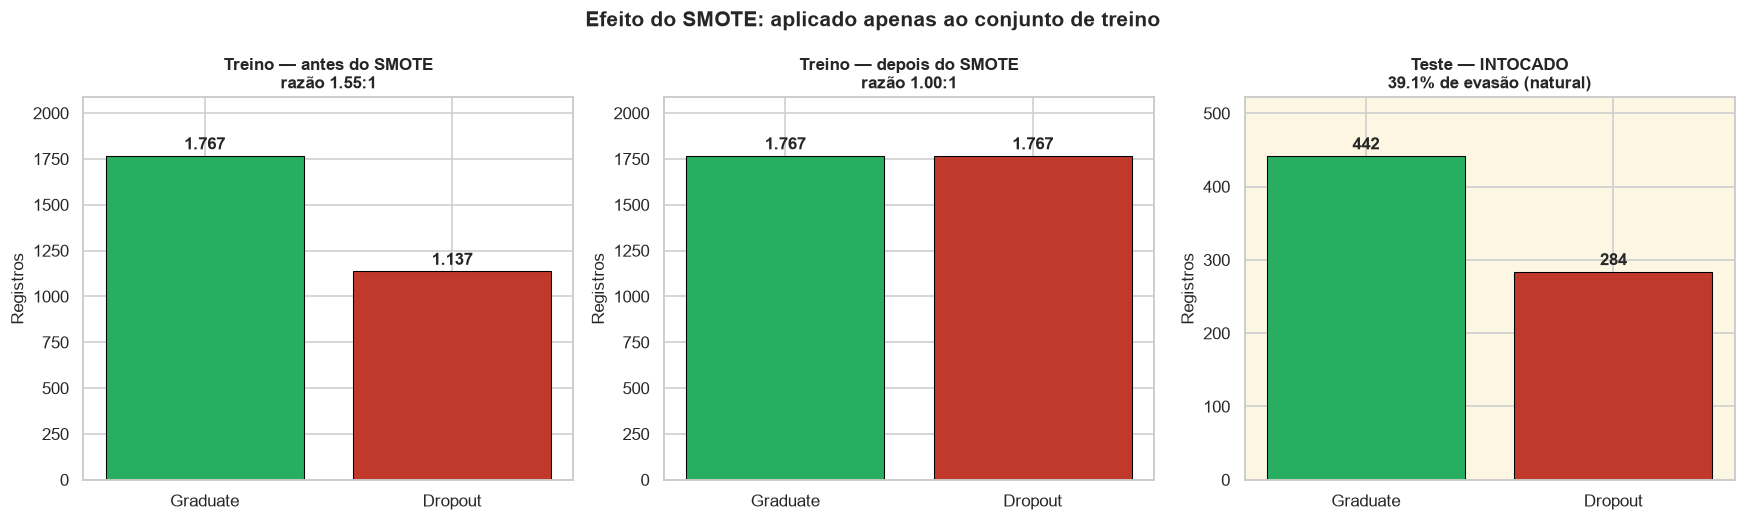

In [10]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.8))

def barras(ax, serie, titulo, subtitulo):
    nomes = [CLASSES[i] for i in serie.index]
    cores = [CORES[n] for n in nomes]
    barras_ = ax.bar(nomes, serie.values, color=cores, edgecolor="black", linewidth=0.7)
    for b, v in zip(barras_, serie.values):
        ax.text(b.get_x() + b.get_width() / 2, v + max(serie.values) * 0.02,
                f"{v:,}".replace(",", "."), ha="center", fontweight="bold")
    ax.set_title(f"{titulo}\n{subtitulo}", fontsize=11)
    ax.set_ylabel("Registros")
    ax.set_ylim(0, max(serie.values) * 1.18)

barras(eixos[0], antes, "Treino — antes do SMOTE",
       f"razão {antes.max() / antes.min():.2f}:1")
barras(eixos[1], depois, "Treino — depois do SMOTE",
       f"razão {depois.max() / depois.min():.2f}:1")
barras(eixos[2], y_teste.value_counts().sort_index(), "Teste — INTOCADO",
       f"{y_teste.mean() * 100:.1f}% de evasão (natural)")

eixos[2].patch.set_facecolor("#fdf6e3")

fig.suptitle("Efeito do SMOTE: aplicado apenas ao conjunto de treino",
             fontsize=14, fontweight="bold")
plt.tight_layout()
salvar("06_efeito_smote.png")
plt.show()

> ### Conclusão parcial — balanceamento
>
> O treino passou de 2.904 para 3.534 registros: **630 alunos sintéticos** da classe `Dropout`,
> levando a razão de 1,55:1 para 1,00:1. O teste permaneceu com 726 registros e 39,1% de evasão.
>
> O painel destacado à direita é intencional: ele documenta visualmente, para a banca, que a
> avaliação final ocorrerá sobre a distribuição real do fenômeno. **Nenhuma métrica reportada neste
> trabalho é calculada sobre dados sintéticos.**

## 7. Diagnóstico de importância das variáveis

Duas medidas complementares, ambas calculadas **somente sobre o treino**:

- **Informação mútua** — mede dependência estatística entre cada variável e o alvo, inclusive não
  linear, mas avaliando uma variável de cada vez;
- **Importância por impureza (Random Forest preliminar)** — mede o quanto cada variável contribui
  para as divisões das árvores, já considerando a interação com as demais.

### Por que nada será descartado

O modelo final precisa ser **interpretável**, e interpretabilidade não é sinônimo de parcimônia.
Uma variável com importância baixa no agregado pode ser decisiva para um subgrupo específico — e é
exatamente esse tipo de leitura individual que o SHAP entrega no Notebook 4. Além disso, com 4.424
observações e ~90 features não há restrição computacional que force a redução.

Esta seção é, portanto, **diagnóstica**: serve para antecipar o que o SHAP deve confirmar e para
detectar antecipadamente qualquer variável suspeita de vazamento. Nenhuma coluna é removida.

In [11]:
# --- Informação mútua --------------------------------------------------------
mi = mutual_info_classif(X_treino, y_treino, random_state=SEED)
mi = pd.Series(mi, index=X_treino.columns, name="info_mutua")

# --- Random Forest preliminar (apenas diagnóstico) ---------------------------
rf_diag = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
rf_diag.fit(X_treino_bal, y_treino_bal)
imp = pd.Series(rf_diag.feature_importances_, index=X_treino.columns, name="importancia_rf")

diagnostico = (
    pd.concat([mi, imp], axis=1)
      .assign(rank_mi=lambda d: d["info_mutua"].rank(ascending=False).astype(int),
              rank_rf=lambda d: d["importancia_rf"].rank(ascending=False).astype(int))
      .sort_values("importancia_rf", ascending=False)
)
diagnostico.insert(0, "variavel", [rotulo(i) for i in diagnostico.index])

print("TOP 15 features por importância no Random Forest preliminar")
display(diagnostico.head(15).round(4))

TOP 15 features por importância no Random Forest preliminar


,variavel,info_mutua,importancia_rf,rank_mi,rank_rf
curricular_units_2nd_sem_approved,Disciplinas aprovadas (2º sem.),0.3130,0.1778,1,1
curricular_units_1st_sem_approved,Disciplinas aprovadas (1º sem.),0.2587,0.1210,2,2
curricular_units_2nd_sem_grade,Média das notas (2º sem.),0.2444,0.1078,3,3
curricular_units_1st_sem_grade,Média das notas (1º sem.),0.2088,0.0621,4,4
tuition_fees_up_to_date,Mensalidades em dia,0.1087,0.0486,5,5
age_at_enrollment,Idade no ingresso,0.0688,0.0307,8,6
curricular_units_2nd_sem_evaluations,Avaliações realizadas (2º sem.),0.0849,0.0293,6,7
scholarship_holder,Bolsista,0.0572,0.0268,9,8
curricular_units_1st_sem_evaluations,Avaliações realizadas (1º sem.),0.0790,0.0249,7,9
admission_grade,Nota de admissão,0.0383,0.0225,14,10


[figura salva] figuras\07_importancia_features.png


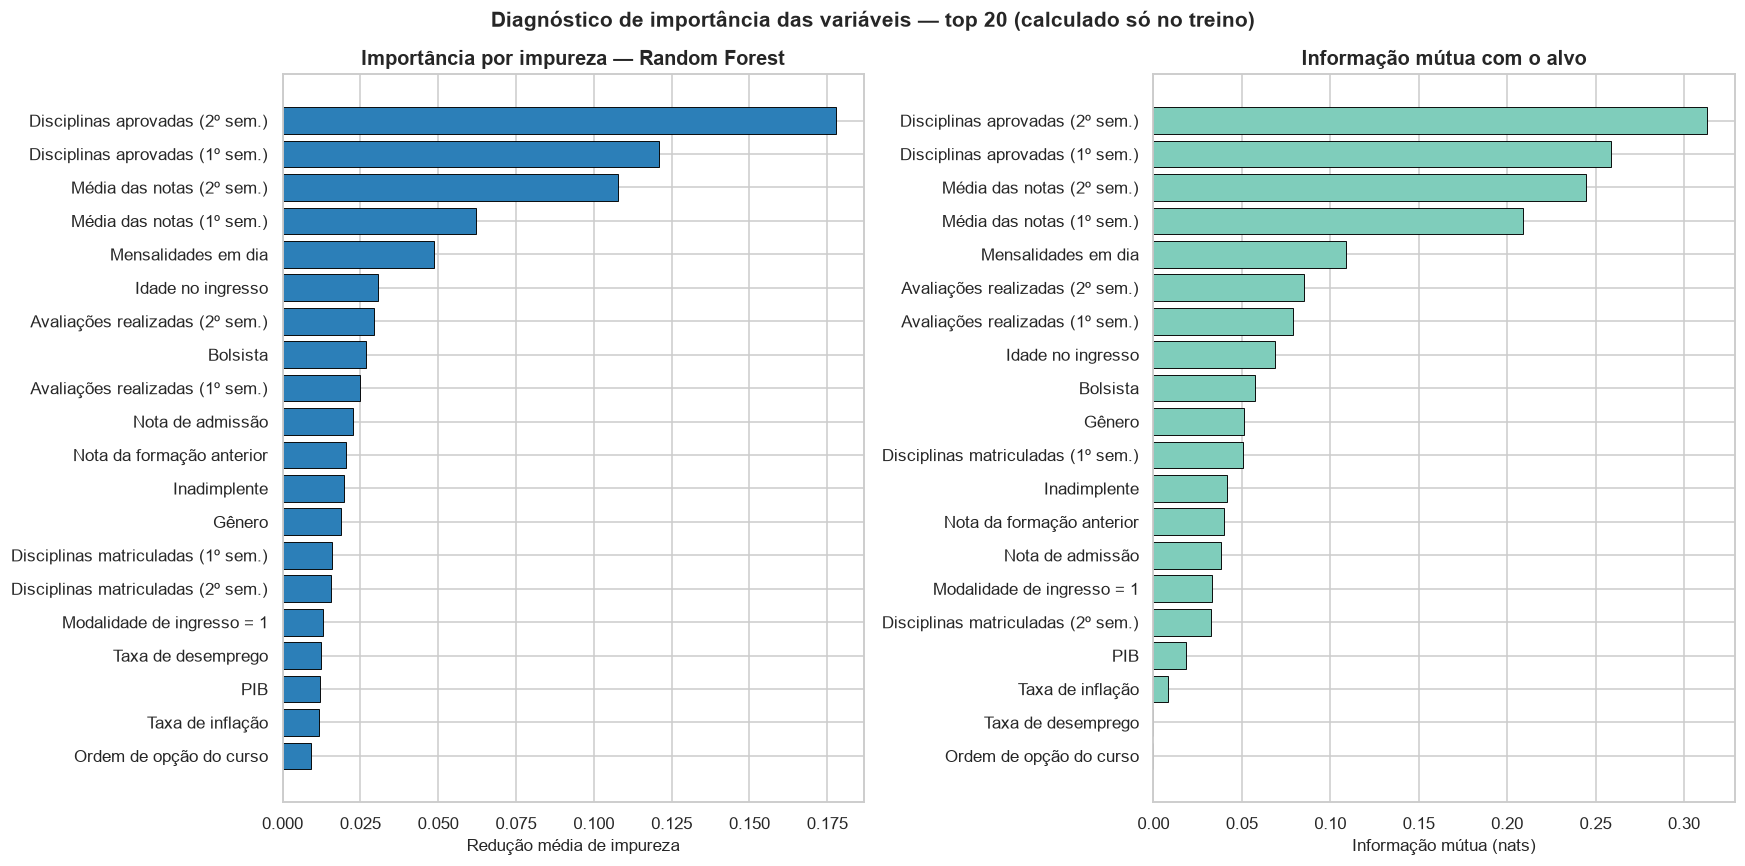

In [12]:
top = diagnostico.head(20)

fig, eixos = plt.subplots(1, 2, figsize=(16, 8))

ordem_rf = top.sort_values("importancia_rf")
eixos[0].barh(ordem_rf["variavel"], ordem_rf["importancia_rf"],
              color="#2c7fb8", edgecolor="black", linewidth=0.6)
eixos[0].set_title("Importância por impureza — Random Forest")
eixos[0].set_xlabel("Redução média de impureza")

ordem_mi = top.sort_values("info_mutua")
eixos[1].barh(ordem_mi["variavel"], ordem_mi["info_mutua"],
              color="#7fcdbb", edgecolor="black", linewidth=0.6)
eixos[1].set_title("Informação mútua com o alvo")
eixos[1].set_xlabel("Informação mútua (nats)")

fig.suptitle("Diagnóstico de importância das variáveis — top 20 (calculado só no treino)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
salvar("07_importancia_features.png")
plt.show()

In [13]:
# --- Concentração da importância ---------------------------------------------
acum = diagnostico["importancia_rf"].cumsum()
for k in (5, 10, 20, 40):
    print(f"   top {k:>2} features concentram {acum.iloc[k - 1] * 100:5.1f}% da importância")

print()
irrelevantes = int((diagnostico["importancia_rf"] < 0.001).sum())
print(f"Features com importância < 0,1%: {irrelevantes} de {len(diagnostico)}")
print("Mantidas no conjunto — ver justificativa acima.")

   top  5 features concentram  51.7% da importância
   top 10 features concentram  65.2% da importância
   top 20 features concentram  80.0% da importância
   top 40 features concentram  89.2% da importância

Features com importância < 0,1%: 19 de 105
Mantidas no conjunto — ver justificativa acima.


> ### Conclusão parcial — importância
>
> As duas medidas convergem, o que reforça a confiança no diagnóstico: as variáveis de **desempenho
> acadêmico do 2º semestre** (aprovações e média) lideram com folga, seguidas pelas do 1º semestre e
> pelas variáveis **financeiras** (mensalidades em dia, inadimplência, bolsa).
>
> Três leituras relevantes para o TCC:
>
> 1. **Confirma o Notebook 1 por outro caminho.** Lá a evidência era correlação linear; aqui é
>    dependência não linear e ganho em partições de árvore. Achados que sobrevivem a métodos
>    diferentes são os que se sustentam na defesa.
> 2. **Nenhuma variável tem importância anômala.** Um preditor isolado que dominasse todos os outros
>    seria sinal de vazamento — não é o caso, a importância se distribui de forma plausível.
> 3. **As dummies aparecem pouco no topo**, o que era esperado: cada uma carrega uma fatia estreita
>    da informação. Isso justifica *a posteriori* a decisão de agrupar categorias raras.
>
> Um alerta que será retomado no Notebook 4: importância por impureza é **enviesada em favor de
> variáveis com muitos valores distintos** e nada diz sobre a *direção* do efeito. É por essa razão
> que o trabalho não se apoia nela como resultado final — o SHAP existe precisamente para corrigir
> essas duas limitações.

## 8. Persistência dos artefatos

São gravados em CSV (formato auditável, legível fora do Python) os quatro conjuntos, mais o
treino **antes** do SMOTE — necessário para que o Notebook 3 possa comparar o efeito do
balanceamento. O pré-processador ajustado vai em `joblib`, pois será preciso para transformar
qualquer aluno novo exatamente como o modelo espera.

In [14]:
sufixo = "" if FORMULACAO == "binaria" else "_multiclasse"

arquivos = {
    f"X_train{sufixo}.csv": X_treino_bal,
    f"y_train{sufixo}.csv": pd.Series(y_treino_bal, name="target"),
    f"X_test{sufixo}.csv": X_teste,
    f"y_test{sufixo}.csv": y_teste.rename("target"),
    f"X_train_sem_smote{sufixo}.csv": X_treino,
    f"y_train_sem_smote{sufixo}.csv": y_treino.rename("target"),
}

for nome, objeto in arquivos.items():
    caminho = os.path.join(DIR_DADOS, nome)
    objeto.to_csv(caminho, index=False)
    forma = objeto.shape if hasattr(objeto, "shape") else (len(objeto),)
    print(f"   [salvo] {caminho:<46} {forma}")

joblib.dump(preprocessador, os.path.join(DIR_MODELOS, f"preprocessador{sufixo}.joblib"))
print(f"   [salvo] {os.path.join(DIR_MODELOS, f'preprocessador{sufixo}.joblib')}")

metadados = {
    "formulacao": FORMULACAO,
    "classes": {str(k): v for k, v in CLASSES.items()},
    "classe_positiva": CLASSES[max(CLASSES)],
    "seed": SEED,
    "n_features": int(X_treino.shape[1]),
    "features": list(X_treino.columns),
    "cols_continuas": COLS_CONTINUAS,
    "cols_binarias": COLS_BINARIAS,
    "cols_nominais": COLS_NOMINAIS,
    "n_treino_antes_smote": int(len(y_treino)),
    "n_treino_apos_smote": int(len(y_treino_bal)),
    "n_teste": int(len(y_teste)),
    "prop_evasao_teste": float(y_teste.mean()),
}
caminho_meta = os.path.join(DIR_DADOS, f"metadados{sufixo}.json")
with open(caminho_meta, "w", encoding="utf-8") as fh:
    json.dump(metadados, fh, ensure_ascii=False, indent=2)
print(f"   [salvo] {caminho_meta}")

   [salvo] dados\X_train.csv                              (3534, 105)
   [salvo] dados\y_train.csv                              (3534,)
   [salvo] dados\X_test.csv                               (726, 105)
   [salvo] dados\y_test.csv                               (726,)


   [salvo] dados\X_train_sem_smote.csv                    (2904, 105)
   [salvo] dados\y_train_sem_smote.csv                    (2904,)
   [salvo] modelos\preprocessador.joblib
   [salvo] dados\metadados.json


In [15]:
# --- Conferência de integridade dos artefatos --------------------------------
Xtr = pd.read_csv(os.path.join(DIR_DADOS, f"X_train{sufixo}.csv"))
ytr = pd.read_csv(os.path.join(DIR_DADOS, f"y_train{sufixo}.csv"))["target"]
Xte = pd.read_csv(os.path.join(DIR_DADOS, f"X_test{sufixo}.csv"))
yte = pd.read_csv(os.path.join(DIR_DADOS, f"y_test{sufixo}.csv"))["target"]

verificacoes = {
    "treino e alvo com o mesmo nº de linhas": len(Xtr) == len(ytr),
    "teste e alvo com o mesmo nº de linhas": len(Xte) == len(yte),
    "mesmas features em treino e teste": list(Xtr.columns) == list(Xte.columns),
    "treino balanceado (razão = 1,00)": abs(ytr.mean() - 0.5) < 1e-9,
    "teste NÃO balanceado (proporção natural)": abs(yte.mean() - 0.5) > 0.05,
    "sem valores ausentes": not (Xtr.isnull().any().any() or Xte.isnull().any().any()),
    "sem valores infinitos": bool(np.isfinite(Xtr.to_numpy()).all() and np.isfinite(Xte.to_numpy()).all()),
}

for descricao, ok in verificacoes.items():
    print(f"   [{'OK' if ok else 'FALHA'}] {descricao}")

assert all(verificacoes.values()), "Há verificação falhando — não prosseguir para o Notebook 3."
print("\nTodos os artefatos estão consistentes.")

   [OK] treino e alvo com o mesmo nº de linhas
   [OK] teste e alvo com o mesmo nº de linhas
   [OK] mesmas features em treino e teste
   [OK] treino balanceado (razão = 1,00)
   [OK] teste NÃO balanceado (proporção natural)
   [OK] sem valores ausentes
   [OK] sem valores infinitos

Todos os artefatos estão consistentes.


## 9. Síntese da Fase 3 do CRISP-DM

### Decisões e justificativas

| Decisão | Escolha | Justificativa central |
|---|---|---|
| Classe `Enrolled` | Removida (binária) | Não é desfecho, é censura à direita; sem fronteira empírica própria |
| Classe positiva | `Dropout` = 1 | Falso negativo é o erro caro; recall precisa ser da evasão |
| Separação | 80/20 estratificada, **primeiro passo** | Impede que qualquer parâmetro veja o teste |
| Contínuas | `StandardScaler` ajustado no treino | Escalas incompatíveis; exigido pela Regressão Logística |
| Binárias | Mantidas em 0/1 | Já padronizadas; preserva legibilidade dos coeficientes |
| Nominais | One-hot com `min_frequency=0,01` | Remove ordenação falsa e controla a dimensionalidade |
| Balanceamento | SMOTE só no treino | Sintético no teste inflaria a métrica |
| Seleção de variáveis | **Nenhuma** | Interpretabilidade exige o quadro completo; sem restrição computacional |

### Resultado

| | |
|---|---|
| Registros | 4.424 → **3.630** (após remover `Enrolled`) |
| Features | 36 colunas originais → **105** (19 contínuas + 8 binárias + 78 dummies) |
| Treino | 2.904 → **3.534** (630 sintéticos), razão 1,00:1 |
| Teste | **726** registros, 39,1% de evasão — intocado |

### Sobre a integridade metodológica

Vale registrar explicitamente, porque é o ponto que uma banca costuma sondar: o SMOTE roda **depois**
da separação, o `StandardScaler` e o `OneHotEncoder` são ajustados **exclusivamente** no treino, e o
diagnóstico de importância também. A célula de verificação da seção 8 confirma que o teste manteve a
proporção natural de evasão — se qualquer uma dessas condições fosse violada, ela falharia e
interromperia a execução.

### Próximo passo

**Notebook 3 — Modelagem:** Regressão Logística (linha de base), Random Forest e XGBoost, com
validação cruzada estratificada de 5 folds e busca de hiperparâmetros otimizando **F1 da classe
`Dropout`**.